In [1]:
import trovolut as trv
import numpy as np 

def make_mats():
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import AllChem
    dmds_smiles = "CSSC"

    # RDKit: SMILES -> mol
    mol = Chem.MolFromSmiles(dmds_smiles)
    mol = Chem.AddHs(mol)  # add hydrogens

    # embed 3D coordinates
    AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())
    AllChem.UFFOptimizeMolecule(mol)

    # extract XYZ as multiline string in standard XYZ format:
    atoms = [atom.GetSymbol() for atom in mol.GetAtoms()]
    conf = mol.GetConformer()

    xyz_lines = []
    xyz_lines.append(str(len(atoms)))
    xyz_lines.append("dmds generated by RDKit")
    for i, sym in enumerate(atoms):
        pos = conf.GetAtomPosition(i)
        xyz_lines.append(f"{sym} {pos.x:.8f} {pos.y:.8f} {pos.z:.8f}")

    dmds_xyz = "\n".join(xyz_lines)

    H_elec = trv.qm.ElectronicHamiltonian.from_xyz(
        xyz_source=dmds_xyz,
        basis="sto-3g",
        charge=0,
        spin_mult=1,
        use_gpu4pyscf=False,
        freeze_core=True,
        n_core_keep=2,
        n_virt_keep=2,
    ).to_qubits()

    hamcoeffs = H_elec.terms()
    mats = [term['coef'] * term['matrix'] for term in hamcoeffs]
    return mats

matrices = make_mats()  
print("Hamiltonian terms:", len(matrices))
print("Size of hamiltonian matrices:", matrices[0].shape)

converged SCF energy = -864.654938672564


/Users/luismantilla/Desktop/UofT/NVIDIA/trovolut/.venv/lib/python3.13/site-packages/pyscf/lib/misc.py:1238: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  random.seed()
<cupynumeric internals>:284: RuntimeWarning: cuPyNumeric has not implemented numpy.kron and is falling back to canonical NumPy. You may notice significantly decreased performance for this function call.

Set CUPYNUMERIC_FALLBACK_STACKTRACE=1 and re-run to include a full stack trace with this warning.


Hamiltonian terms: 349
Size of hamiltonian matrices: (256, 256)


In [2]:
matrices = make_mats()
norms = [np.linalg.norm(mat) for mat in matrices]
# print size of matrices, how many terms, and norms
print("Hamiltonian terms:", len(matrices))
print("Size of hamiltonian matrices:", matrices[0].shape)
print("Norms of Hamiltonian terms:", norms)

converged SCF energy = -864.654938666712
Hamiltonian terms: 249
Size of hamiltonian matrices: (256, 256)
Norms of Hamiltonian terms: [np.float64(371122.58851488814), np.float64(1208.4113247877872), np.float64(3.0198867357863262e-12), np.float64(3.0198867357863262e-12), np.float64(1208.4113247877872), np.float64(3.0198867357863274e-12), np.float64(3.0198867357863274e-12), np.float64(1203.867500271404), np.float64(0.00028017986230351774), np.float64(0.00028017986230351774), np.float64(0.5778379750818887), np.float64(0.5778379750818887), np.float64(1203.867500271404), np.float64(0.0002801798623035176), np.float64(0.0002801798623035176), np.float64(0.5778379750818887), np.float64(0.5778379750818887), np.float64(1366.0138362451946), np.float64(1.1129719675866483), np.float64(1.1129719675866483), np.float64(1366.0138362451946), np.float64(1.1129719675866483), np.float64(1.1129719675866483), np.float64(1154.318421379122), np.float64(1154.318421379122), np.float64(0.5475090142521709), np.float

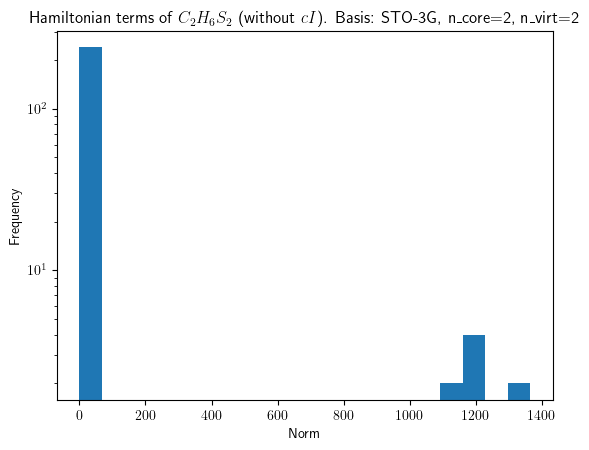

In [21]:
# histogram of norms
import matplotlib.pyplot as plt
# render in latex
plt.rcParams['text.usetex'] = True

plt.hist(norms[1:], bins=20)
plt.xlabel("Norm")
plt.ylabel("Frequency")
# logscale
# plt.xscale("log")
plt.yscale("log")
plt.title(rf'Hamiltonian terms of $C_2H_6S_2$ (without  $c I $). Basis: STO-3G, n_core=2, n_virt=2')
plt.show()
